In [1]:
from api import maniskill
from api.video import show
from api.jenga import EXAMPLE_DESIGN, GRID_ORIGIN, SETTLE_TIME, STABILITY_TOL, built_occupancy, check_stability
from api.jenga_core import format_design, overlap_score
import matplotlib.pyplot as plt
import numpy as np
import torch

TASK = "JengaDesign-v1"

/workspace/control-proj/control/.venv/lib/python3.11/site-packages/sapien/_vulkan_tricks.py:78: UserWarning: Failed to find Vulkan ICD file. This is probably due to an incorrect or partial installation of the NVIDIA driver. SAPIEN will attempt to provide an ICD file anyway but it may not work.
  warn(


/workspace/control-proj/control/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Target: the 11-block worked example (api.jenga.EXAMPLE_DESIGN), 5 / 3 / 3 horizontal blocks in layers k = 0 / 1 / 2.
# Indexing: design[i, j, k], i -> world +x, j -> world +y, k -> world +z (k = 0 on the table).
# format_design prints each layer with +y up and +x right, i.e. in the orientation of the hand sketch.
print(format_design(EXAMPLE_DESIGN))

# Stability check (spec section 5): teleport every block to its design pose, run physics for SETTLE_TIME s,
# and require that every block drifts less than STABILITY_TOL.
stab = check_stability(EXAMPLE_DESIGN)
print(f"\nstable={stab.stable} (settle {SETTLE_TIME}s, tol {STABILITY_TOL * 1000:.0f} mm), "
      f"max drift {stab.max_dev.max() * 1000:.2f} mm")

layer k=0
   .  4  4  4  .
   1  .  2  .  3
   1  .  2  .  3
   1  .  2  .  3
   .  5  5  5  .
layer k=1
   .  .  .  .  .
   6  6  6  .  .
   .  .  7  7  7
   8  8  8  .  .
   .  .  .  .  .
layer k=2
   .  .  .  .  .
   9 10  .  .  .
   9 10 11 11 11
   9 10  .  .  .
   .  .  .  .  .



stable=True (settle 1.0s, tol 5 mm), max drift 0.03 mm


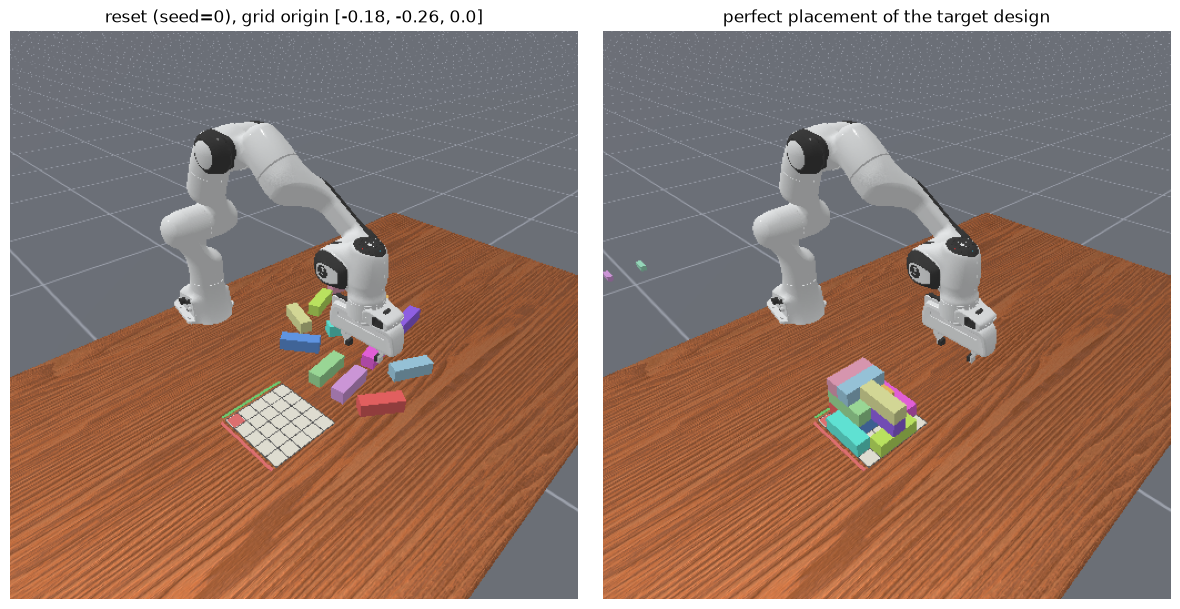

In [3]:
# Left: reset scene for the demo seed: scattered blocks on the robot's left (+y), 5x5 grid marker on its right (-y).
# Grid marker: red cell = design cell [0, 0]; red stripe runs along +i (x), green stripe along +j (y).
# Right: the perfect placement, every design block teleported to its exact design pose (no physics; spare
# blocks are parked off the table).
env = maniskill.make_env(TASK, num_envs=1, render=True)
env.reset(seed=0)
reset_img = env.render()[0].cpu().numpy()
env.unwrapped.place_design()
target_img = env.render()[0].cpu().numpy()
env.close()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, img, title in [
    (axes[0], reset_img, f"reset (seed=0), grid origin {GRID_ORIGIN.tolist()}"),
    (axes[1], target_img, "perfect placement of the target design"),
]:
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(title)
plt.tight_layout()
plt.show()

In [4]:
# Demonstration: motion-planned scripted solver (api.jenga_solver.solve_jenga) using privileged block poses,
# building the design bottom-up, layer by layer. Recorded once for seed=0 into <repo>/demos/<task>/motionplanning/
# (same workflow as StackThree-v1). Only regenerated if that file is missing.
import gymnasium as gym
from mani_skill.utils.wrappers.record import RecordEpisode

from api.jenga_solver import format_results, solve_jenga

demo_dir = maniskill.REPO_DEMO_DIR / TASK / "motionplanning"
if not (demo_dir / "trajectory.h5").exists():
    gen_env = maniskill.make_env(TASK, obs_mode="none", control_mode="pd_joint_pos")
    gen_env = RecordEpisode(
        gen_env, output_dir=str(demo_dir), trajectory_name="trajectory", save_video=False,
        source_type="motionplanning", source_desc="JengaDesign-v1 scripted solver",
        record_reward=False, save_on_reset=False,
    )
    res = solve_jenga(gen_env, seed=0)
    gen_env.flush_trajectory()
    gen_env.close()
    print(format_results(res))

In [5]:
# Open-loop replay of the recorded demo from its exact reset kwargs.
demo = maniskill.load_demo(TASK)
print(f"{len(demo.actions)} actions, control_mode={demo.control_mode}, recorded success={demo.success}")

env = maniskill.make_env(TASK, num_envs=1, render=True, control_mode=demo.control_mode,
                         max_episode_steps=len(demo.actions) + 1)
env.reset(**demo.reset_kwargs)
frames = [env.render()[0].cpu().numpy()]
for t, a in enumerate(demo.actions):
    _, _, _, _, info = env.step(torch.from_numpy(a).unsqueeze(0))
    if t % 2 == 1:  # every other frame keeps the embedded video small
        frames.append(env.render()[0].cpu().numpy())
show(frames, fps=env.unwrapped.control_freq / 2)

1910 actions, control_mode=pd_joint_pos, recorded success=True


In [6]:
# Achieved occupancy (each block -> the 3 cells holding most of its mass) and the v1 cell-overlap score.
occ = built_occupancy(env)
print(format_design(occ.astype(int)))
score = overlap_score(EXAMPLE_DESIGN, occ)
print(f"\nscore = {score} / {int((EXAMPLE_DESIGN != 0).sum())}   (env info: {info['score'].item()}, success={info['success'].item()})")
print("cells built but not in target:", int((occ & (EXAMPLE_DESIGN == 0)).sum()))
env.close()

layer k=0
   .  1  1  1  .
   1  .  1  .  1
   1  .  1  .  1
   1  .  1  .  1
   .  1  1  1  .
layer k=1
   .  .  .  .  .
   1  1  1  .  .
   .  .  1  1  1
   1  1  1  .  .
   .  .  .  .  .
layer k=2
   .  .  .  .  .
   1  1  .  .  .
   1  1  1  1  1
   1  1  .  .  .
   .  .  .  .  .

score = 33 / 33   (env info: 33, success=True)
cells built but not in target: 0
